# 1. Dipendenze e librerie

In [ ]:
#!pip install -q transformers datasets evaluate scikit-learn accelerate
#!pip install torch
from datasets import load_dataset, concatenate_datasets
from huggingface_hub import login
import os
import torch
#login("hf_YourTokenHere")
SEED = 42
from transformers import (
    AutoTokenizer, 
    AutoModelForSequenceClassification, 
    TrainingArguments, 
    Trainer,
    DataCollatorWithPadding,
    pipeline
)
import evaluate
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns
device = 0 if torch.cuda.is_available() else -1
from peft import get_peft_model, LoraConfig, TaskType
import numpy as np

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 105.6 MB/s eta 0:00:0000:010:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have cuda-core 1.0.1 which is incompatible.
dask-cuda 26.2.0 requires numba-cuda<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
distributed-ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cuml-cu12 26.2.0 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which is incompatible.
cuml-cu12 26.2.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cu

# 2. Preparazione del dataset 
1. Caricamento del dataset wikimedia/wikipedia subset 20231101.it limitato a 400 righe
2. Eliminazione delle colonne "id", "url" e "title"
3. Aggiunta della colonna "label" impostata a 0
4. Riduzione del testo a 2 paragrafi

In [2]:
# 1
dataset_classe_0 = load_dataset("wikimedia/wikipedia", "20231101.it", split="train[:1000]")

# 2
columns_to_remove = [col for col in dataset_classe_0.column_names if col != "text"]
dataset_classe_0 = dataset_classe_0.remove_columns(columns_to_remove)

# 3
labels = [0] * len(dataset_classe_0)
dataset_classe_0 = dataset_classe_0.add_column("label", labels)

# 4
def applica_taglio(t):
    num_paragrafi = 1  # Numero di paragrafi da estrarre
    # Divide il testo in una lista di paragrafi usando il doppio a capo
    paragrafi = t['text'].split('\n\n')
    
    # Filtra i paragrafi vuoti e conserva solo quelli validi
    # p.strip() restituirà una stringa vuota se il paragrafo è composto solo da spazi bianchi, quindi viene filtrato
    paragrafi = [p.strip() for p in paragrafi if p.strip()]
    paragrafi_validi = paragrafi[:num_paragrafi]
    # Sostituisce il testo vecchio con quello nuovo
    t['text'] = '\n\n'.join(paragrafi_validi)
    return t

dataset_classe_0 = dataset_classe_0.map(applica_taglio)

# Verifica
print("Struttura del dataset della classe 0:")
print(dataset_classe_0)

print("\nEsempi estratti:\n")
for i in range(4):
    print(f"Text: {dataset_classe_0[i]['text']}")
    print(f"Label: {dataset_classe_0[i]['label']}")
    print("-" * 70)

README.md: 0.00B [00:00, ?B/s]

20231101.it/train-00000-of-00010.parquet:   0%|          | 0.00/529M [00:00<?, ?B/s]

20231101.it/train-00001-of-00010.parquet:   0%|          | 0.00/376M [00:00<?, ?B/s]

20231101.it/train-00002-of-00010.parquet:   0%|          | 0.00/340M [00:00<?, ?B/s]

20231101.it/train-00003-of-00010.parquet:   0%|          | 0.00/287M [00:00<?, ?B/s]

...

20231101.it/train-00008-of-00010.parquet:   0%|          | 0.00/220M [00:00<?, ?B/s]

20231101.it/train-00009-of-00010.parquet:   0%|          | 0.00/257M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/1833639 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Struttura del dataset della classe 0:
Dataset({
    features: ['text', 'label'],
    num_rows: 1000
})

Esempi estratti:

Text: Larmonium, o harmonium, è un tipo di organo a serbatoio d'aria con una (o più) tastiere e due pedali per azionare i mantici per l'aria. Il suono è prodotto da una o più file di ance libere, analogamente alla fisarmonica e all'armonica a bocca.
Label: 0
----------------------------------------------------------------------
Text: Lantropologia (dal greco ἄνθρωπος ànthropos «uomo» e λόγος, lògos «discorso, dottrina» quindi letteralmente: «studio dell'uomo») è una branca scientifica sviluppatasi in particolar modo in epoca moderna che studia l'essere umano sotto diverse prospettive (sociale, culturale, morfologica, psicoevolutiva, sociologica, artistico-espressiva, filosofico-religiosa), indagando i suoi vari comportamenti all'interno della società. Nata come disciplina interna alla biologia, ha acquisito in seguito anche un importante valore umanistico.
Label: 0


5. Caricamento del dataset MelmaGrigia/italian-text-sentiment-analysis
6. Filtro il dataset per emozioni "anger", "surprise" e "joy" che simulano il tono scandalistico o personale
7. Seleziono 298 righe per bilanciare il dataset
8. Rimuovo le colonne "label" e "label_name"
9. Aggiungo la colonna "label" impostata a 1

In [3]:
# 5
dataset_emozioni = load_dataset("MelmaGrigia/italian-text-sentiment-analysis", split="train")

# 6
emozioni_target = ["anger", "surprise", "joy"]
dataset_emozioni = dataset_emozioni.filter(lambda x: x['label_name'] in emozioni_target)

# 7
dataset_emozioni = dataset_emozioni.select(range(298))
# 8
colonne_da_rimuovere = [col for col in dataset_emozioni.column_names if col != "text"]
dataset_emozioni = dataset_emozioni.remove_columns(colonne_da_rimuovere)

# 9
labels = [1] * len(dataset_emozioni)
dataset_emozioni = dataset_emozioni.add_column("label", labels)

# Verifica
print("Struttura del dataset della classe 1:")
print(dataset_emozioni)

print("\nEsempi estratti:")
print(dataset_emozioni[0])
print(dataset_emozioni[1])

README.md:   0%|          | 0.00/186 [00:00<?, ?B/s]

train.csv: 0.00B [00:00, ?B/s]

test.csv: 0.00B [00:00, ?B/s]

Generating train split:   0%|          | 0/1799 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/326 [00:00<?, ? examples/s]

Filter:   0%|          | 0/1799 [00:00<?, ? examples/s]

Flattening the indices:   0%|          | 0/298 [00:00<?, ? examples/s]

Struttura del dataset della classe 1:
Dataset({
    features: ['text', 'label'],
    num_rows: 298
})

Esempi estratti:
{'text': 'Che giornata fantastica! Non potrei essere più felice.', 'label': 1}
{'text': 'Sono furioso per come mi hanno trattato!', 'label': 1}


10. Caricamento del dataset tanaos/synthetic-spam-detection-dataset-italian
11. Filtro il dataset solo per le pubblicità ("labels" == 1)
12. Seleziono 298 righe
13. Rinomino la colonna "labels" in "label"

In [4]:
# 10
dataset_pubblicita = load_dataset("tanaos/synthetic-spam-detection-dataset-italian", split="train")

# 11
dataset_pubblicita = dataset_pubblicita.filter(lambda x: x['labels'] == 1)

# 12
dataset_pubblicita = dataset_pubblicita.select(range(298))

# 13
dataset_pubblicita = dataset_pubblicita.rename_column("labels", "label")

# Verifica
print("Struttura del dataset della classe 1:")
print(dataset_pubblicita)

print("\nEsempi estratti:")
print(dataset_pubblicita[0])
print(dataset_pubblicita[1])

README.md: 0.00B [00:00, ?B/s]

data.csv: 0.00B [00:00, ?B/s]

Generating train split:   0%|          | 0/18719 [00:00<?, ? examples/s]

Filter:   0%|          | 0/18719 [00:00<?, ? examples/s]

Struttura del dataset della classe 1:
Dataset({
    features: ['text', 'label'],
    num_rows: 298
})

Esempi estratti:
{'text': 'Offerta limitata! Guadagna 5000 euro al giorno con il nostro metodo segreto, clicca subito!', 'label': 1}
{'text': 'Attenzione! Il tuo account è stato selezionato per una ricompensa di 10.000 euro. Fornisci i tuoi dati per riscuotere il premio.', 'label': 1}


14. Unione del dataset pubblicità, del dataset emotivo e del dataset sintetico nel dataset di classe 0

In [6]:
# 14
dataset_aggiuntivo = load_dataset("csv", data_files="/kaggle/input/datasets/marioanthonyguerrera/dataset-classe1-aggiuntivo/spam_pubblicita_italiano.csv", split="train")
dataset_classe_1 = concatenate_datasets([dataset_emozioni, dataset_pubblicita, dataset_aggiuntivo])
dataset_classe_1 = dataset_classe_1.shuffle(seed=SEED)

# Verifica
print("Struttura del dataset di classe 1:")
print(dataset_classe_1)

print("\nEsempi estratti:")
print(dataset_classe_1[0])
print(dataset_classe_1[1])
print(dataset_classe_1[2])
print(dataset_classe_1[3])

Struttura del dataset di classe 1:
Dataset({
    features: ['text', 'label'],
    num_rows: 1000
})

Esempi estratti:
{'text': 'Nel campo della fonetica acustica, il rumore bianco è definito come un segnale contenente tutte le frequenze udibili dallo spettro umano riprodotte con la medesima potenza. Questa particolarità gli permette di mascherare efficacemente i suoni improvvisi provenienti dall’ambiente circostante, motivo per cui viene ampiamente utilizzato negli ospedali per favorire il sonno dei pazienti o negli uffici open space per garantire la privacy delle conversazioni e limitare le distrazioni visive e uditive. Se fai fatica ad addormentarti a causa del traffico cittadino o dei vicini rumorosi, acquista il nostro nuovo generatore di suoni ambientali compatto di design. Con oltre trenta tracce rilassanti preimpostate e un timer di spegnimento automatico intelligente, rivoluzionerai la qualità del tuo riposo notturno.', 'label': 1}
{'text': 'Incredibile affare immobiliare in zo

15. Unione dei due dataset e shuffle

In [8]:
# 15
dataset_finale = concatenate_datasets([dataset_classe_0, dataset_classe_1])
dataset_finale = dataset_finale.shuffle(seed=SEED)

# Verifica
print("Struttura del dataset finale:")
print(dataset_finale)

conteggio_label_0 = dataset_finale.filter(lambda riga: riga['label'] == 0).num_rows
conteggio_label_1 = dataset_finale.filter(lambda riga: riga['label'] == 1).num_rows

print(f"\nRighe con label 0: {conteggio_label_0}")
print(f"Righe con label 1: {conteggio_label_1}")

print("\n\nEsempi estratti:\n")
print(dataset_finale[0])
print(dataset_finale[1])
print(dataset_finale[2])
print(dataset_finale[3])

Struttura del dataset finale:
Dataset({
    features: ['text', 'label'],
    num_rows: 2000
})


Filter:   0%|          | 0/2000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/2000 [00:00<?, ? examples/s]


Righe con label 0: 1000
Righe con label 1: 1000


Esempi estratti:

{'text': 'Offerta limitata: acquistando questo prodotto ricevi un viaggio gratuito alle Maldive, clicca ora!', 'label': 1}
{'text': 'Botanica\n Aa – genere della famiglia delle Orchidacee', 'label': 0}
{'text': 'Aumenta la tua massa muscolare del 40% in poche settimane senza dover passare ore in palestra. La nostra formula esclusiva approvata dai bodybuilder professionisti stimola la produzione naturale di testosterone e migliora la resistenza fisica. Clicca qui per acquistare il tuo kit di potenziamento muscolare con uno sconto speciale.', 'label': 1}
{'text': "Il ferro è l'elemento chimico di numero atomico 26. Il suo simbolo è Fe, dal latino ferrum. Il ferro fu conosciuto fin dall'antichità e, per le sue qualità di durezza, tenacia e resilienza, la sua importanza per l'umanità ha contrassegnato un'intera era: la cosiddetta «età del ferro» viene fatta iniziare dalla fine del II millennio a.C. (XII secolo a.C.); solo

# 3. Plotting del dataset

Primi 5 records:                                                 text  label
0  Offerta limitata: acquistando questo prodotto ...      1
1  Botanica\n Aa – genere della famiglia delle Or...      0
2  Aumenta la tua massa muscolare del 40% in poch...      1
3  Il ferro è l'elemento chimico di numero atomic...      0
4  Il crivello di Eratostene è un antico algoritm...      0
----------------------------------------------------------------------


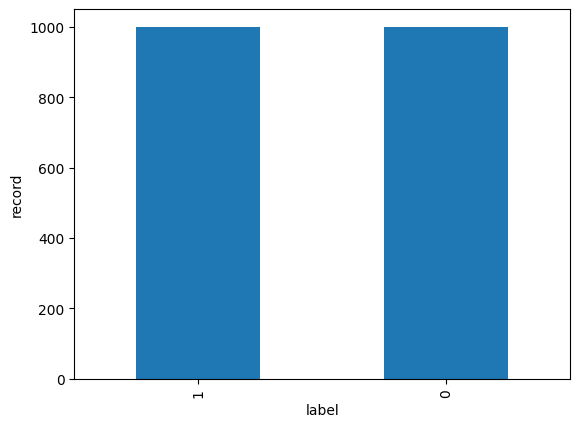

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

df = dataset_finale.to_pandas()
print("Primi 5 records:", df.head())
print("-" * 70)
value_counts = df['label'].value_counts()
value_counts.plot(kind='bar')
plt.xlabel('label')
plt.ylabel('record')
plt.show()

# 4. Splitting del dataset

In [10]:
dataset = dataset_finale.train_test_split(test_size=0.2, seed=1)
# dataset['train'] sarà l' 80% del dataset, mentre dataset['test'] sarà il 20% del dataset
# Splittiamo dataset['train'] in temp['train'] e temp['test']
temp = dataset['train'].train_test_split(test_size=0.2, seed=1)
dataset['train'] = temp['train']
dataset['validation'] = temp['test']
print(dataset)
train = dataset["train"].shuffle(seed=SEED)
val = dataset["test"].shuffle(seed=SEED)
test = dataset["test"].shuffle(seed=SEED + 1)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 1280
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 400
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 320
    })
})


# 5. Definizione delle label

In [11]:
label_names = ["divulgativo", "pubblicitario"]
id2label = {0: "divulgativo", 1: "pubblicitario"}
label2id = {"divulgativo": 0, "pubblicitario": 1}

# 6. Esecuzione della Baseline sul test set
1. Definizione della pipeline
2. Esecuzione zero-shot sul modello xlm-roberta-large-xnli

In [12]:
print("\nEsecuzione Zero-Shot sul Test Set...\n")

# 1
classifier = pipeline(
    "zero-shot-classification",
    model="joeddav/xlm-roberta-large-xnli",
    device=device
)

# 2
prediction_label = []
for item in test:
    text = item["text"]
    result = classifier(text, candidate_labels=label_names)
    # 'result' contiene le etichette ordinate per probabilità decrescente.
    # best_label è la più probabile
    best_label = result['labels'][0]
    prediction_label.append(label2id[best_label])

true_label = [item["label"] for item in test]
print("Esecuzione completata\n")

config.json:   0%|          | 0.00/734 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/2.24G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

XLMRobertaForSequenceClassification LOAD REPORT from: joeddav/xlm-roberta-large-xnli
Key                             | Status     |  | 
--------------------------------+------------+--+-
roberta.embeddings.position_ids | UNEXPECTED |  | 
roberta.pooler.dense.weight     | UNEXPECTED |  | 
roberta.pooler.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]


Esecuzione Zero-Shot sul Test Set...



You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Esecuzione completata



# 7. Valutazioni Baseline
1. Visualizzazione report
2. Visualizzazione matrice di confusione
3. Error Analysis


--- Risultati Baseline Zero-Shot (Nessun Fine-Tuning) ---
               precision    recall  f1-score   support

  divulgativo       0.52      0.68      0.59       192
pubblicitario       0.59      0.43      0.50       208

     accuracy                           0.55       400
    macro avg       0.56      0.55      0.55       400
 weighted avg       0.56      0.55      0.54       400



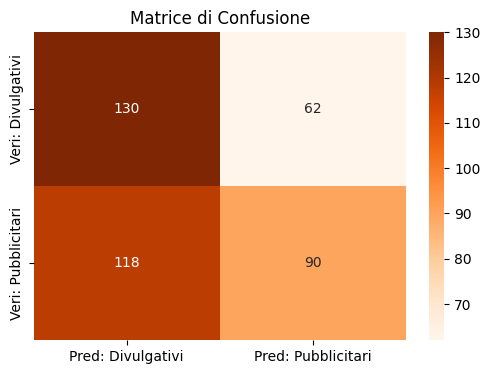


--- ANALISI DEGLI ERRORI (Falsi Positivi e Falsi Negativi) ---
Numero totale di errori: 180
----------------------------------------------------------------------
Tipo: FALSO NEGATIVO (Scambiato per Divulgazione)
Testo: Che incredibile coincidenza incontrare il mio migliore amico d'infanzia dopo 30 anni!
Etichetta Vera: pubblicitario
Etichetta Predetta: divulgativo
----------------------------------------------------------------------
Tipo: FALSO NEGATIVO (Scambiato per Divulgazione)
Testo: Sono così frustrato che potrei urlare al mondo intero!
Etichetta Vera: pubblicitario
Etichetta Predetta: divulgativo
----------------------------------------------------------------------
Tipo: FALSO NEGATIVO (Scambiato per Divulgazione)
Testo: La collaborazione a distanza tra i membri di un team richiede strumenti di comunicazione affidabili e veloci. La nostra suite di produttività include chat aziendali, sistemi di videoconferenza in alta definizione e spazi di archiviazione condivisi per lavora

In [10]:
# 1
print("\n--- Risultati Baseline Zero-Shot (Nessun Fine-Tuning) ---")
print(classification_report(true_label, prediction_label, target_names=label_names))

# 2
cm = confusion_matrix(true_label, prediction_label)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', xticklabels=['Pred: Divulgativi', 'Pred: Pubblicitari'], yticklabels=['Veri: Divulgativi', 'Veri: Pubblicitari'])
plt.title('Matrice di Confusione')
plt.show()

# 3
errori = sum(1 for v, p in zip(true_label, prediction_label) if v != p)
print(f"\n--- ANALISI DEGLI ERRORI (Falsi Positivi e Falsi Negativi) ---")
print(f"Numero totale di errori: {errori}")
print("-" * 70)
for idx, item in enumerate(test.select(range(20))):
    vera = true_label[idx]
    predetta = prediction_label[idx]
    if vera != predetta:
        testo_estratto = item['text']
        tipo_errore = "FALSO POSITIVO (Scambiato per Pubblicità)" if predetta == 1 else "FALSO NEGATIVO (Scambiato per Divulgazione)"
        print(f"Tipo: {tipo_errore}")
        print(f"Testo: {testo_estratto}")
        print(f"Etichetta Vera: {label_names[vera]}")
        print(f"Etichetta Predetta: {label_names[predetta]}")
        print("-" * 70)

# 7. Tokenizzazione del dataset
1. Definizione del modello
2. Inizializza il tokenizer associato al modello
3. Definisce la funzione che prende in input un batch e applica il tokenizer al campo "text"
4. Applica la funzione all'intero dataset con map
5. Rimuove la colonna "text"
6. Converte il dataset tokenizzato in tensori
7. Definisce il data_collator che inserisce il padding dinamicamente ai batch del dataset
8. Stampa il dataset tokenizzato

In [14]:
# 1
MODEL_CHECKPOINT = "osiria/roberta-base-italian"

# 2
tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT)

# 3
def preprocess_function(examples):
    return tokenizer(examples["text"], truncation=True, max_length=512)

# 4
tokenized_datasets = dataset.map(preprocess_function, batched=True)

# 5
tokenized_datasets = tokenized_datasets.remove_columns(["text"])

# 6
tokenized_datasets.set_format("torch")

# 7
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# 8
print(tokenized_datasets)

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/415 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/1280 [00:00<?, ? examples/s]

Map:   0%|          | 0/400 [00:00<?, ? examples/s]

Map:   0%|          | 0/320 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['label', 'input_ids', 'attention_mask'],
        num_rows: 1280
    })
    test: Dataset({
        features: ['label', 'input_ids', 'attention_mask'],
        num_rows: 400
    })
    validation: Dataset({
        features: ['label', 'input_ids', 'attention_mask'],
        num_rows: 320
    })
})


# 8. Definizione metriche di valutazione

In [ ]:
acc_metric = evaluate.load("accuracy")
f1_metric = evaluate.load("f1")
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    acc = acc_metric.compute(predictions=preds, references=labels)["accuracy"]
    f1 = f1_metric.compute(predictions=preds, references=labels, average="macro")["f1"]
    return {"accuracy": acc, "macro_f1": f1}

# 9. Ricerca Iperparametri

In [12]:
import gc

grid_search_configs = [
    {'r': 8, 'lr': 1e-4},
    {'r': 16, 'lr': 1e-4},
    {'r': 8, 'lr': 2e-4},
    {'r': 16, 'lr': 5e-5}
]

best_accuracy = 0
best_config = {}

print("---------Ricerca degli iperparametri migliori sul Validation set---------\n")

for config in grid_search_configs:
    lr = config['lr']
    rank = config['r']
    
    print(f"---------Training con learning rate: {lr} e LoRA rank: {rank}---------")
    
    base_model_search = AutoModelForSequenceClassification.from_pretrained(
        MODEL_CHECKPOINT, 
        num_labels=2, 
        id2label=id2label, 
        label2id=label2id
    )
    
    lora_config_search = LoraConfig(
        r=rank,
        lora_alpha=rank * 2,
        target_modules=["query", "value"],
        lora_dropout=0.1,
        bias="none",
        task_type=TaskType.SEQ_CLS
    )

    model_lora_search = get_peft_model(base_model_search, lora_config_search)
    if torch.cuda.is_available():
        model_lora_search.cuda()
    
    training_args_search = TrainingArguments(
        output_dir=f"./lora_search_lr{lr}_r{rank}",
        learning_rate=lr,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=16,
        num_train_epochs=2,
        logging_dir="./logs",
        logging_strategy="epoch",
        eval_strategy="epoch",
        save_strategy="no",
        report_to="none",
    )

    trainer_search = Trainer(
        model=model_lora_search,
        args=training_args_search,
        train_dataset=tokenized_datasets["train"],
        eval_dataset=tokenized_datasets["validation"],
        processing_class=tokenizer,
        data_collator=data_collator,
        compute_metrics=compute_metrics,
    )

    trainer_search.train()
    eval_metrics = trainer_search.evaluate()
    current_acc = eval_metrics["eval_accuracy"]
    current_f1 = eval_metrics["eval_macro_f1"]

    print(f"Valutazione con learning rate: {lr} e LoRA rank: {rank}")
    print(f"Accuracy: {current_acc:.4f}, Macro F1: {current_f1:.4f}\n")
    
    if current_acc > best_accuracy:
        best_accuracy = current_acc
        best_config = {'learning_rate': lr, 'lora_rank': rank}
        trainer_search.save_model("./roberta_lora_best")
    del model_lora_search, base_model_search, trainer_search
    torch.cuda.empty_cache()
    gc.collect()

print(f"\n{'-'*70}")
print(f"RICERCA COMPLETATA!")
print(f"La configurazione vincente sul Validation Set è:")
print(f"Learning Rate: {best_config['learning_rate']}")
print(f"LoRA Rank (r): {best_config['lora_rank']}")
print(f"Con una Accuracy di: {best_accuracy:.4f}")
print(f"Il modello migliore è stato salvato in './roberta_lora_best'")
print(f"{'-'*70}")

---------Ricerca degli iperparametri migliori sul Validation set---------



---------Training con learning rate: 0.0001 e LoRA rank: 8---------


model.safetensors:   0%|          | 0.00/500M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: osiria/roberta-base-italian
Key                             | Status     | 
--------------------------------+------------+-
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
classifier.dense.weight         | MISSING    | 
classifier.out_proj.weight      | MISSING    | 
classifier.out_proj.bias        | MISSING    | 
classifier.dense.bias           | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
`logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` ins

...

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: osiria/roberta-base-italian
Key                             | Status     | 
--------------------------------+------------+-
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
classifier.dense.weight         | MISSING    | 
classifier.out_proj.weight      | MISSING    | 
classifier.out_proj.bias        | MISSING    | 
classifier.dense.bias           | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
`logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` ins

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,1.376792,1.353930,0.668750,0.668750
2,1.317711,1.306035,0.646875,0.642090


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Valutazione con learning rate: 5e-05 e LoRA rank: 16
Accuracy: 0.6469, Macro F1: 0.6421


----------------------------------------------------------------------
RICERCA COMPLETATA!
La configurazione vincente sul Validation Set è:
Learning Rate: 0.0001
LoRA Rank (r): 16
Con una Accuracy di: 0.6906
Il modello migliore è stato salvato in './roberta_lora_best'
----------------------------------------------------------------------


# 10. Inizializzazione del Modello e Configurazione LoRA
1. Inizializza il modello e installa la nuova testa
2. Definizione degli iperparametri LoRA
3. Congela i pesi e sovrappone le matrici A e B

In [13]:
N_EPOCHS = 3
LR = 1e-4

# 1
base_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_CHECKPOINT,
    num_labels=2,
    id2label=id2label,
    label2id=label2id
)

# 2
lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    target_modules=["query", "value"],
    lora_dropout=0.1,
    bias="none",
    task_type=TaskType.SEQ_CLS
)

# 3
model_lora = get_peft_model(base_model, lora_config)
model_lora.print_trainable_parameters()

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: osiria/roberta-base-italian
Key                             | Status     | 
--------------------------------+------------+-
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
classifier.dense.weight         | MISSING    | 
classifier.out_proj.weight      | MISSING    | 
classifier.out_proj.bias        | MISSING    | 
classifier.dense.bias           | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 1,181,954 || all params: 126,140,164 || trainable%: 0.9370


# 9. Configurazione del Trainer

In [17]:
training_args = TrainingArguments(
    output_dir="./roberta_lora_output",
    learning_rate=LR,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=N_EPOCHS,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_dir="./logs",
    logging_strategy="epoch",
    report_to="none",
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    greater_is_better=True,
)

trainer_lora = Trainer(
    model=model_lora,
    args=training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

`logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.


NameError: name 'model_lora' is not defined

# 10. Fine-tuning LoRA
1. Carica i pesi in VRAM
2. Avvia il training

In [15]:
# 1
if torch.cuda.is_available():
    model_lora.cuda()

# 2
print("Avvio del training LoRA...")
trainer_lora.train()

Avvio del training LoRA...


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,1.351348,1.184372,0.650000,0.647300
2,1.174719,1.236593,0.703125,0.703122
3,1.130173,1.173959,0.687500,0.687060


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


TrainOutput(global_step=120, training_loss=1.2187465667724608, metrics={'train_runtime': 178.2092, 'train_samples_per_second': 21.548, 'train_steps_per_second': 0.673, 'total_flos': 1017003957936384.0, 'train_loss': 1.2187465667724608, 'epoch': 3.0})

# 11. Valutazioni fine-tuning con LoRA
1. Visualizzazione report
2. Visualizzazione matrice di confusione


Valutazione sul Test Set:


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


LoRA Accuracy: 0.7150


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]



--- Risultati LoRA Fine-Tuned ---
               precision    recall  f1-score   support

  divulgativo       0.71      0.68      0.70       192
pubblicitario       0.72      0.75      0.73       208

     accuracy                           0.71       400
    macro avg       0.71      0.71      0.71       400
 weighted avg       0.71      0.71      0.71       400



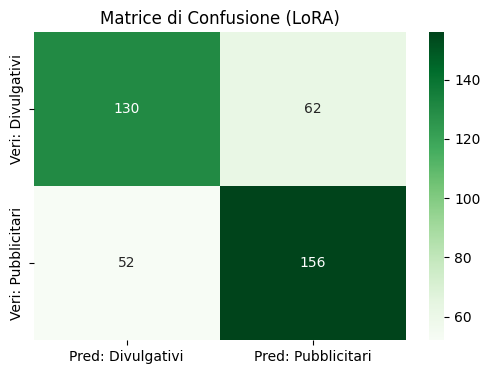

In [16]:
# 1
print("\nValutazione sul Test Set:")
lora_result = trainer_lora.evaluate(tokenized_datasets["test"])
print(f"LoRA Accuracy: {lora_result['eval_accuracy']:.4f}")
predictions_output = trainer_lora.predict(tokenized_datasets["test"])
lora_preds = np.argmax(predictions_output.predictions, axis=-1)
lora_true = predictions_output.label_ids
print("\n--- Risultati LoRA Fine-Tuned ---")
print(classification_report(lora_true, lora_preds, target_names=label_names))

# 2
cm_lora = confusion_matrix(lora_true, lora_preds)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_lora, annot=True, fmt='d', cmap='Greens', xticklabels=['Pred: Divulgativi', 'Pred: Pubblicitari'], yticklabels=['Veri: Divulgativi', 'Veri: Pubblicitari'])
plt.title('Matrice di Confusione (LoRA)')
plt.show()

# 12. Salvataggio del modello in "roberta_lora.zip"

In [17]:
trainer_lora.save_model("./roberta_lora_final")
!zip -r roberta_lora.zip ./roberta_lora_final

  adding: roberta_lora_final/ (stored 0%)
  adding: roberta_lora_final/adapter_config.json (deflated 57%)
  adding: roberta_lora_final/training_args.bin (deflated 53%)
  adding: roberta_lora_final/tokenizer_config.json (deflated 52%)
  adding: roberta_lora_final/README.md (deflated 66%)
  adding: roberta_lora_final/tokenizer.json (deflated 70%)
  adding: roberta_lora_final/adapter_model.safetensors (deflated 7%)


# 13. Inizializzazione del modello per il full fine tuning

In [15]:
N_EPOCHS = 3
LR = 1e-5

full_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_CHECKPOINT,
    num_labels=2,
    id2label=id2label,
    label2id=label2id
)

trainable_params = sum(p.numel() for p in full_model.parameters() if p.requires_grad)
print(f"Parametri totali da addestrare: {trainable_params:,}")

model.safetensors:   0%|          | 0.00/500M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: osiria/roberta-base-italian
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.weight            | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
classifier.out_proj.bias        | MISSING    | 
classifier.dense.bias           | MISSING    | 
classifier.dense.weight         | MISSING    | 
classifier.out_proj.weight      | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Parametri totali da addestrare: 124,958,210


# 14. Configurazione Full fine-tuning

In [16]:
training_args_full = TrainingArguments(
    output_dir="./roberta_full_ft_output",
    learning_rate=LR,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=N_EPOCHS,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_dir="./logs_full",
    logging_strategy="epoch",
    report_to="none",
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    greater_is_better=True,
)

trainer_full = Trainer(
    model=full_model,
    args=training_args_full,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

`logging_dir` is deprecated and will be removed in v5.2. Please set `TENSORBOARD_LOGGING_DIR` instead.


# 15. Avvio Full fine-tuning

In [17]:
if torch.cuda.is_available():
    full_model.cuda()

print("Avvio del Full Fine-Tuning...")
trainer_full.train()

Avvio del Full Fine-Tuning...


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,1.306425,1.207975,0.700000,0.699707
2,1.091784,1.103199,0.731250,0.729464
3,0.904495,0.895280,0.787500,0.786088


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['roberta.embeddings.LayerNorm.weight', 'roberta.embeddings.LayerNorm.bias', 'roberta.encoder.layer.0.attention.output.LayerNorm.weight', 'roberta.encoder.layer.0.attention.output.LayerNorm.bias', 'roberta.encoder.layer.0.output.LayerNorm.weight', 'roberta.encoder.layer.0.output.LayerNorm.bias', 'roberta.encoder.layer.1.attention.output.LayerNorm.weight', 'roberta.encoder.layer.1.attention.output.LayerNorm.bias', 'roberta.encoder.layer.1.output.LayerNorm.weight', 'roberta.encoder.layer.1.output.LayerNorm.bias', 'roberta.encoder.layer.2.attention.output.LayerNorm.weight', 'roberta.encoder.layer.2.attention.output.LayerNorm.bias', 'roberta.encoder.layer.2.output.LayerNorm.weight', 'roberta.encoder.layer.2.output.LayerNorm.bias', 'roberta.encoder.layer.3.attention.output.LayerNorm.weight', 'roberta.encoder.layer.3.attention.output.LayerNorm.bias', 'roberta.encoder.layer.3.output.LayerNorm.weight', 'roberta.encoder.layer.3.output.Laye

TrainOutput(global_step=120, training_loss=1.10090119043986, metrics={'train_runtime': 209.2255, 'train_samples_per_second': 18.353, 'train_steps_per_second': 0.574, 'total_flos': 1003160231882880.0, 'train_loss': 1.10090119043986, 'epoch': 3.0})

# 16. Valutazioni Full fine-tuning


Valutazione sul Test Set (Full FT):


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Full FT Accuracy: 0.8150
Full FT Macro F1: 0.8149


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]



--- Risultati Full Fine-Tuned ---
               precision    recall  f1-score   support

  divulgativo       0.80      0.82      0.81       192
pubblicitario       0.83      0.81      0.82       208

     accuracy                           0.81       400
    macro avg       0.81      0.82      0.81       400
 weighted avg       0.82      0.81      0.82       400



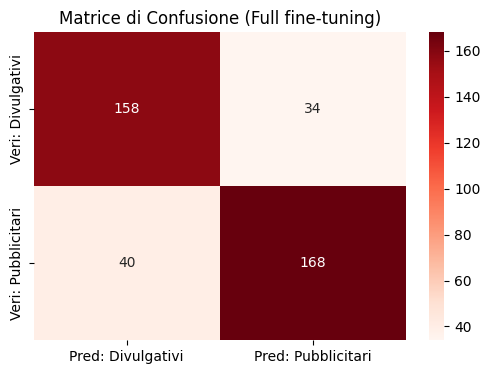

In [18]:
print("\nValutazione sul Test Set (Full FT):")
full_ft_result = trainer_full.evaluate(tokenized_datasets["test"])
print(f"Full FT Accuracy: {full_ft_result['eval_accuracy']:.4f}")
print(f"Full FT Macro F1: {full_ft_result['eval_macro_f1']:.4f}")

predictions_output = trainer_full.predict(tokenized_datasets["test"])
full_preds = np.argmax(predictions_output.predictions, axis=-1)
full_true = predictions_output.label_ids

print("\n--- Risultati Full Fine-Tuned ---")
print(classification_report(full_true, full_preds, target_names=label_names))

cm_full = confusion_matrix(full_true, full_preds)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_full, annot=True, fmt='d', cmap='Reds', xticklabels=['Pred: Divulgativi', 'Pred: Pubblicitari'], yticklabels=['Veri: Divulgativi', 'Veri: Pubblicitari'])
plt.title('Matrice di Confusione (Full fine-tuning)')
plt.show()

# 17. Salvataggio del modello in "roberta_full.zip"

In [22]:
trainer_full.save_model("./roberta_full")
!zip -r roberta_full.zip ./roberta_full

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  adding: roberta_full/ (stored 0%)
  adding: roberta_full/training_args.bin (deflated 53%)
  adding: roberta_full/tokenizer_config.json (deflated 52%)
  adding: roberta_full/tokenizer.json (deflated 70%)
  adding: roberta_full/config.json (deflated 53%)
  adding: roberta_full/model.safetensors (deflated 16%)
